In [3]:
import numpy as np
import pandas as pd
import torch
import transformers
import datasets
import shap
import lime
import importlib.metadata

print(f"numpy:        {np.__version__}")
print(f"pandas:       {pd.__version__}")
print(f"torch:        {torch.__version__}")
print(f"transformers: {transformers.__version__}")
print(f"datasets:     {datasets.__version__}")
print(f"shap:         {shap.__version__}")

try:
    lime_version = importlib.metadata.version("lime")
    print(f"lime:         {lime_version}")
except importlib.metadata.PackageNotFoundError:
    print("lime:         Installed (version not found via metadata)")

numpy:        2.4.6
pandas:       2.2.3
torch:        2.14.1+cpu
transformers: 5.22.1
datasets:     4.8.5
shap:         0.54.1
lime:         0.2.0.1


In [4]:
# ============================================================
# CELL 2: Data + model + baseline
# ============================================================
from datasets import load_dataset
from transformers import pipeline

sst = load_dataset("stanfordnlp/sst2")["validation"]      # 872 sentences
sentences = list(sst["sentence"])
labels    = np.array(sst["label"])                         # 0 = NEG, 1 = POS

clf = pipeline(
    "text-classification",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    top_k=None,
    device=-1,           # CPU
)

def predict_proba(texts):
    """Return array [n, 2] = [P(NEG), P(POS)]."""
    if isinstance(texts, str):
        texts = [texts]
    out = clf(texts, batch_size=32, truncation=True, max_length=512)
    probs = []
    for d in out:
        p = {item["label"]: item["score"] for item in d}
        probs.append([p["NEGATIVE"], p["POSITIVE"]])
    return np.array(probs)

# ---- accuracy vs baseline ----
probs_all = predict_proba(sentences)
preds_all = (probs_all[:, 1] > 0.5).astype(int)
acc       = (preds_all == labels).mean()
baseline  = max(labels.mean(), 1 - labels.mean())

print(f"DistilBERT accuracy : {acc:.4f}")
print(f"Majority baseline    : {baseline:.4f}")
print(f"Sentences            : {len(sentences)}")
print(f"Positive proportion  : {labels.mean():.3f}")
print(f"High-confidence (P>0.99) proportion: {(probs_all.max(axis=1) > 0.99).mean():.3f}")

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (7 outputs left out)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

DistilBERT accuracy : 0.9106
Majority baseline    : 0.5092
Sentences            : 872
Positive proportion  : 0.509
High-confidence (P>0.99) proportion: 0.844


In [5]:
# ============================================================
# CELL 3: Helpers
# ============================================================
import re

def normalize_word(w):
    """Lowercase, strip punctuation — used to compare word sets across methods."""
    return re.sub(r"[^\w']", "", w.lower())

def top_k_words(weight_dict, k=5):
    """Return top-k words by |weight| from a {word: weight} dict."""
    return [w for w, _ in sorted(weight_dict.items(), key=lambda kv: abs(kv[1]), reverse=True)[:k]]

def jaccard(a, b):
    """Jaccard overlap of two word sets (after normalisation)."""
    A = {normalize_word(w) for w in a if normalize_word(w)}
    B = {normalize_word(w) for w in b if normalize_word(w)}
    if not A and not B:
        return 1.0
    return len(A & B) / len(A | B)

print("Helpers ready.")

Helpers ready.


In [6]:
# ============================================================
# CELL 4: Q1 — LIME
# ============================================================
from lime.lime_text import LimeTextExplainer

lime_explainer = LimeTextExplainer(class_names=["NEGATIVE", "POSITIVE"])

# Stratified-ish sample of 50 sentences (seed fixed)
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(sentences), size=50, replace=False)
sample_texts = [sentences[i] for i in sample_idx]

lime_top = {}      # idx -> list of top-5 words
lime_full = {}     # idx -> {word: weight}

for j, (i, text) in enumerate(zip(sample_idx, sample_texts)):
    exp = lime_explainer.explain_instance(
        text,
        predict_proba,
        num_features=10,
        num_samples=300,       # kept modest for CPU speed
        labels=(1,),           # explain P(POSITIVE)
    )
    try:
        weights = dict(exp.as_list(label=1))
    except TypeError:
        weights = dict(exp.as_list())
    lime_full[i] = weights
    lime_top[i]  = top_k_words(weights, k=5)
    if (j + 1) % 10 == 0:
        print(f"  LIME {j+1}/50 done")

print("LIME finished.")
print("Example (first sentence):")
print("  ", sample_texts[0])
print("  top-5:", lime_top[sample_idx[0]])

  LIME 10/50 done
  LIME 20/50 done
  LIME 30/50 done
  LIME 40/50 done
  LIME 50/50 done
LIME finished.
Example (first sentence):
   it deserves to be seen by anyone with even a passing interest in the events shaping the world beyond their own horizons . 
  top-5: [np.str_('a'), np.str_('world'), np.str_('with'), np.str_('even'), np.str_('by')]


In [8]:
# ============================================================
# CELL 5: Q1 — SHAP (Partition SHAP with whitespace masker)
# ============================================================
# SHAP needs a function returning a scalar per text.
# We convert inputs explicitly to Python strings to handle numpy string types passed by SHAP.
def f_pos(texts):
    clean_texts = [str(t) for t in texts]
    return predict_proba(clean_texts)[:, 1]

masker = shap.maskers.Text(r"\s+")             # whitespace tokenisation
shap_explainer = shap.Explainer(f_pos, masker, algorithm="partition")

# Use 30 sentences from the same sample (SHAP is heavier than LIME)
shap_idx = sample_idx[:30]
shap_texts = [sentences[i] for i in shap_idx]

shap_values = shap_explainer(shap_texts, max_evals=150, silent=True)

# Extract top-5 words per sentence
shap_top = {}
for k, i in enumerate(shap_idx):
    tokens = list(shap_values[k].data)
    vals   = np.array(shap_values[k].values).flatten()
    weights = {tok: v for tok, v in zip(tokens, vals)}
    shap_top[i] = top_k_words(weights, k=5)

print("SHAP finished.")
print("Example (same sentence as LIME):")
print("  ", sentences[sample_idx[0]])
print("  top-5:", shap_top.get(sample_idx[0], "not in SHAP sample"))

SHAP finished.
Example (same sentence as LIME):
   it deserves to be seen by anyone with even a passing interest in the events shaping the world beyond their own horizons . 
  top-5: ['passing ', 'deserves ', 'even ', 'with ', 'a ']


In [9]:
# ============================================================
# CELL 6: Q1 — Occlusion (leave-one-word-out)
# ============================================================
def occlusion_weights(text):
    """Drop in P(POS) when each word is removed."""
    base = predict_proba([text])[0, 1]
    words = text.split()
    if len(words) <= 1:
        return {w: 0.0 for w in words}
    weights = {}
    for j, w in enumerate(words):
        perturbed = " ".join(words[:j] + words[j+1:])
        p = predict_proba([perturbed])[0, 1]
        weights[w] = base - p          # positive = word pushes toward POSITIVE
    return weights

occ_idx = shap_idx[:20]                 # 20 sentences is enough
occ_top = {}
for i in occ_idx:
    w = occlusion_weights(sentences[i])
    occ_top[i] = top_k_words(w, k=5)

print("Occlusion finished.")

Occlusion finished.


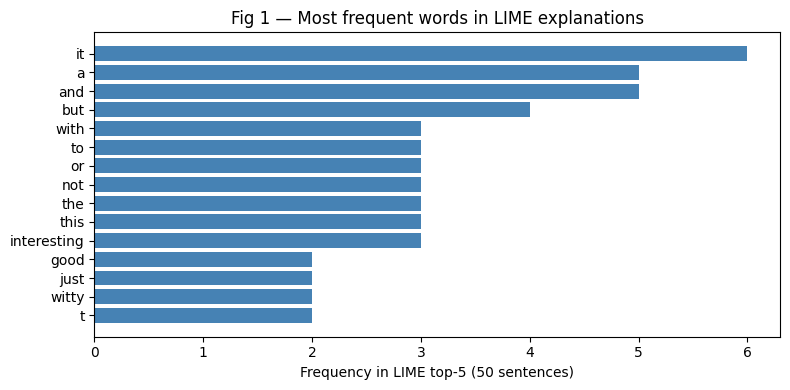

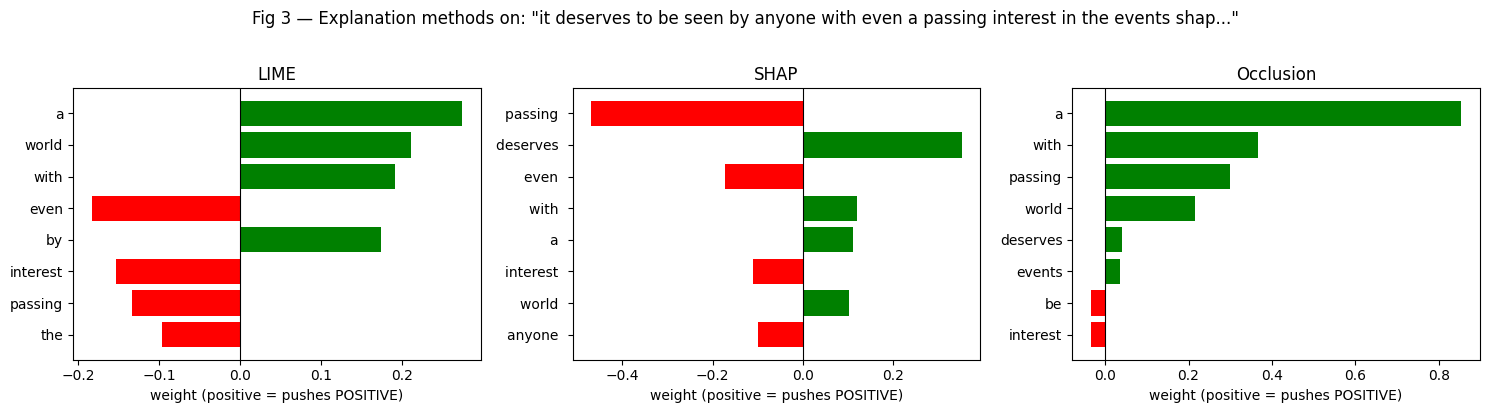

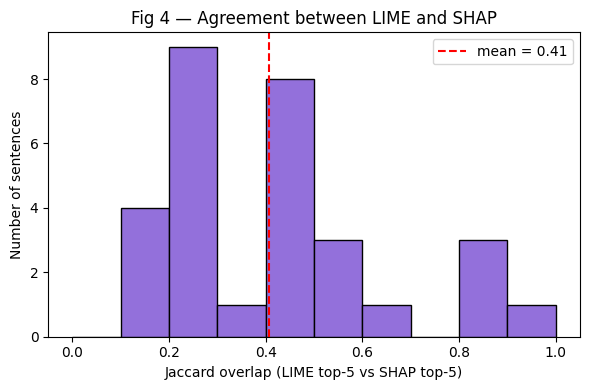

Mean Jaccard (LIME vs SHAP) = 0.407
Median                      = 0.429
Sentences with overlap 0    = 0/30


In [11]:
# ============================================================
# CELL 7: Q1 — Agreement + FIG 1, FIG 2, FIG 3, FIG 4
# ============================================================
import os
from collections import Counter
import matplotlib.pyplot as plt

# Ensure figures directory exists
os.makedirs("figures", exist_ok=True)

# ---- shared indices for LIME vs SHAP ----
shared_idx = [i for i in shap_idx if i in lime_top]

# FIG 1: most frequent LIME top words across the 50-sentence sample
all_top_words = [w for lst in lime_top.values() for w in lst]
word_freq = Counter(normalize_word(w) for w in all_top_words if normalize_word(w))
top15 = word_freq.most_common(15)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([w for w, _ in top15][::-1], [c for _, c in top15][::-1], color="steelblue")
ax.set_xlabel("Frequency in LIME top-5 (50 sentences)")
ax.set_title("Fig 1 — Most frequent words in LIME explanations")
plt.tight_layout()
plt.savefig("figures/fig1_lime_top_words.pdf", bbox_inches="tight")
plt.savefig("figures/fig1_lime_top_words.png", dpi=150, bbox_inches="tight")
plt.show()

# FIG 2: SHAP text plot for 3 chosen sentences (chosen from shap_idx specifically)
# We must resolve their indices relative to the SHAP sample to avoid ValueErrors
shap_idx_list = list(shap_idx)
probs_shap = predict_proba(shap_texts)[:, 1]

pos_easy = shap_idx_list[int(np.argmax(probs_shap))]
neg_easy = shap_idx_list[int(np.argmin(probs_shap))]
uncertain = shap_idx_list[int(np.argmin(np.abs(probs_shap - 0.5)))]

fig = plt.figure(figsize=(10, 6))
shap.plots.text(shap_values[[shap_idx_list.index(pos_easy)]], display=False)
plt.savefig("figures/fig2a_shap_positive.pdf", bbox_inches="tight")
plt.savefig("figures/fig2a_shap_positive.png", dpi=150, bbox_inches="tight")
plt.close(fig)

fig = plt.figure(figsize=(10, 6))
shap.plots.text(shap_values[[shap_idx_list.index(neg_easy)]], display=False)
plt.savefig("figures/fig2b_shap_negative.pdf", bbox_inches="tight")
plt.savefig("figures/fig2b_shap_negative.png", dpi=150, bbox_inches="tight")
plt.close(fig)

fig = plt.figure(figsize=(10, 6))
shap.plots.text(shap_values[[shap_idx_list.index(uncertain)]], display=False)
plt.savefig("figures/fig2c_shap_uncertain.pdf", bbox_inches="tight")
plt.savefig("figures/fig2c_shap_uncertain.png", dpi=150, bbox_inches="tight")
plt.close(fig)

# FIG 3: side-by-side LIME vs SHAP vs Occlusion for ONE sentence
example_i = sample_idx[0]
example_text = sentences[example_i]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

def plot_weights(ax, weights, title):
    items = sorted(weights.items(), key=lambda kv: abs(kv[1]), reverse=True)[:8]
    words = [w for w, _ in items][::-1]
    vals  = [v for _, v in items][::-1]
    colors = ["green" if v > 0 else "red" for v in vals]
    ax.barh(words, vals, color=colors)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("weight (positive = pushes POSITIVE)")

plot_weights(axes[0], lime_full[example_i], "LIME")
plot_weights(axes[1], {t: v for t, v in zip(shap_values[0].data, np.array(shap_values[0].values).flatten())}, "SHAP")
plot_weights(axes[2], occlusion_weights(example_text), "Occlusion")
fig.suptitle(f"Fig 3 — Explanation methods on: \"{example_text[:80]}...\"", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig3_method_comparison.pdf", bbox_inches="tight")
plt.savefig("figures/fig3_method_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# FIG 4: Jaccard overlap between LIME and SHAP top-5
overlaps = [jaccard(lime_top[i], shap_top[i]) for i in shared_idx]

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(overlaps, bins=np.linspace(0, 1, 11), edgecolor="k", color="mediumpurple")
ax.axvline(np.mean(overlaps), color="red", ls="--", label=f"mean = {np.mean(overlaps):.2f}")
ax.set_xlabel("Jaccard overlap (LIME top-5 vs SHAP top-5)")
ax.set_ylabel("Number of sentences")
ax.set_title("Fig 4 — Agreement between LIME and SHAP")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig4_lime_shap_agreement.pdf", bbox_inches="tight")
plt.savefig("figures/fig4_lime_shap_agreement.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Mean Jaccard (LIME vs SHAP) = {np.mean(overlaps):.3f}")
print(f"Median                      = {np.median(overlaps):.3f}")
print(f"Sentences with overlap 0    = {sum(o == 0 for o in overlaps)}/{len(overlaps)}")

Fig 5 / Fig 6 data:
        delta_lime  delta_shap  delta_rand
mean        0.3973      0.4351      0.0670
median      0.0720      0.2151      0.0006

Flip rates:
flip_lime    0.40
flip_shap    0.46
flip_rand    0.08
dtype: float64

Wilcoxon (LIME vs random ΔP): stat=121.00, p=4.95e-08


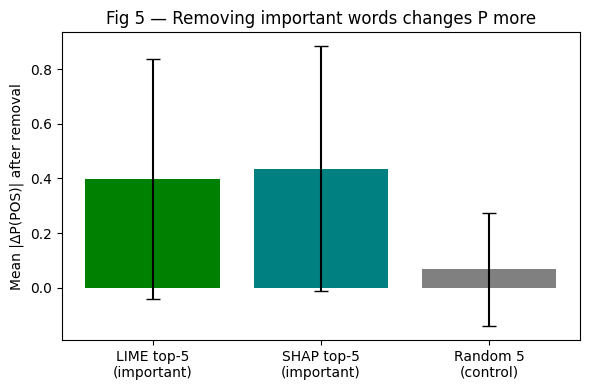

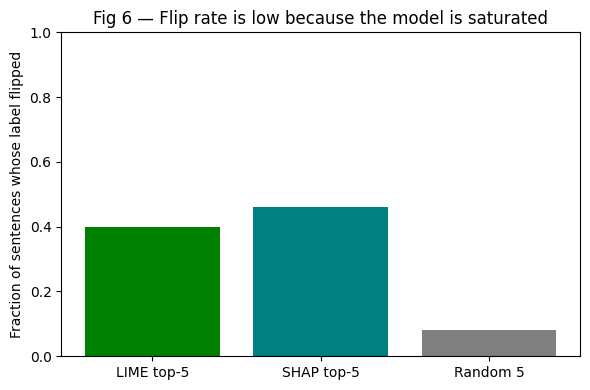

In [12]:
# ============================================================
# CELL 8: Q2 — Faithfulness via deletion (important vs random)
# ============================================================
q2_idx = [i for i in sample_idx if i in lime_top][:50]    # 50 sentences

def remove_words(text, words_to_remove):
    remove_set = {normalize_word(w) for w in words_to_remove}
    return " ".join(w for w in text.split() if normalize_word(w) not in remove_set)

records = []
for i in q2_idx:
    text = sentences[i]
    p0 = predict_proba([text])[0, 1]
    label0 = int(p0 > 0.5)

    # Condition 1: remove LIME top-5
    imp_words = lime_top[i]
    p_imp = predict_proba([remove_words(text, imp_words)])[0, 1]

    # Condition 2: remove SHAP top-5 (check)
    shp_words = shap_top.get(i, imp_words)
    p_shp = predict_proba([remove_words(text, shp_words)])[0, 1]

    # Condition 3: remove 5 random NON-important words
    all_words = text.split()
    non_imp = [w for w in all_words if normalize_word(w) not in {normalize_word(x) for x in imp_words}]
    if len(non_imp) >= 5:
        rng_i = np.random.default_rng(SEED + i)
        rand_words = list(rng_i.choice(non_imp, size=5, replace=False))
    else:
        rand_words = non_imp
    p_rand = predict_proba([remove_words(text, rand_words)])[0, 1]

    records.append({
        "idx": i,
        "p0": p0,
        "delta_lime": abs(p0 - p_imp),
        "delta_shap": abs(p0 - p_shp),
        "delta_rand": abs(p0 - p_rand),
        "flip_lime": int((p_imp > 0.5) != (label0 > 0.5)),
        "flip_shap": int((p_shp > 0.5) != (label0 > 0.5)),
        "flip_rand": int((p_rand > 0.5) != (label0 > 0.5)),
    })

df_q2 = pd.DataFrame(records)

summary = df_q2[["delta_lime", "delta_shap", "delta_rand"]].agg(["mean", "median"]).round(4)
flips = df_q2[["flip_lime", "flip_shap", "flip_rand"]].mean().round(3)
print("Fig 5 / Fig 6 data:")
print(summary)
print("\nFlip rates:")
print(flips)

# Paired comparison: important vs random
from scipy.stats import wilcoxon
stat, p = wilcoxon(df_q2["delta_lime"], df_q2["delta_rand"])
print(f"\nWilcoxon (LIME vs random ΔP): stat={stat:.2f}, p={p:.2e}")

# FIG 5: bar chart mean |ΔP|
fig, ax = plt.subplots(figsize=(6, 4))
means = [df_q2["delta_lime"].mean(), df_q2["delta_shap"].mean(), df_q2["delta_rand"].mean()]
errs  = [df_q2["delta_lime"].std(),  df_q2["delta_shap"].std(),  df_q2["delta_rand"].std()]
ax.bar(["LIME top-5\n(important)", "SHAP top-5\n(important)", "Random 5\n(control)"],
       means, yerr=errs, capsize=5, color=["green", "teal", "grey"])
ax.set_ylabel("Mean |ΔP(POS)| after removal")
ax.set_title("Fig 5 — Removing important words changes P more")
plt.tight_layout()
plt.savefig("figures/fig5_deltaP.pdf", bbox_inches="tight")
plt.savefig("figures/fig5_deltaP.png", dpi=150, bbox_inches="tight")
plt.show()

# FIG 6: flip rates
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["LIME top-5", "SHAP top-5", "Random 5"],
       [df_q2["flip_lime"].mean(), df_q2["flip_shap"].mean(), df_q2["flip_rand"].mean()],
       color=["green", "teal", "grey"])
ax.set_ylabel("Fraction of sentences whose label flipped")
ax.set_ylim(0, 1)
ax.set_title("Fig 6 — Flip rate is low because the model is saturated")
plt.tight_layout()
plt.savefig("figures/fig6_flip_rate.pdf", bbox_inches="tight")
plt.savefig("figures/fig6_flip_rate.png", dpi=150, bbox_inches="tight")
plt.show()

Sentiment pairs: mean |ΔP| = 0.0 max = 0.0001 flips = 0 / 30
Neutral pairs  : mean |ΔP| = 0.0054 flips = 0 / 5


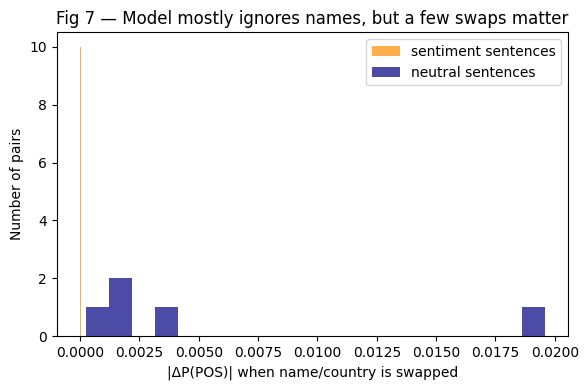


Top-3 pairs with largest ΔP:

  A: 'I hated the film from France.'  P(POS)=0.000
  B: 'I hated the film from Brazil.'  P(POS)=0.001
  |ΔP| = 0.000
  LIME top words for A: [np.str_('hated'), np.str_('film'), np.str_('France'), np.str_('I'), np.str_('the')]

  A: 'I hated the film from Brazil.'  P(POS)=0.001
  B: 'I hated the film from France.'  P(POS)=0.000
  |ΔP| = 0.000
  LIME top words for A: [np.str_('hated'), np.str_('Brazil'), np.str_('film'), np.str_('I'), np.str_('from')]

  A: 'I hated the film from Egypt.'  P(POS)=0.000
  B: 'I hated the film from Japan.'  P(POS)=0.000
  |ΔP| = 0.000
  LIME top words for A: [np.str_('hated'), np.str_('Egypt'), np.str_('film'), np.str_('the'), np.str_('I')]


In [13]:
# ============================================================
# CELL 9: Q3 — Controlled name/country swaps + FIG 7
# ============================================================
# 30 controlled pairs: same sentiment, one slot swapped
COUNTRIES = ["France", "Germany", "Italy", "Spain", "Japan",
             "Brazil", "India", "China", "Mexico", "Egypt"]
NAMES     = ["John", "Maria", "Ahmed", "Yuki", "Pierre",
             "Priya", "Chen", "Carlos", "Fatima", "Anna"]

# Template pairs
template_pairs = []
for k in range(10):
    template_pairs.append((f"I loved the film from {COUNTRIES[k]}.",
                           f"I loved the film from {COUNTRIES[(k+5) % 10]}."))
    template_pairs.append((f"I hated the film from {COUNTRIES[k]}.",
                           f"I hated the film from {COUNTRIES[(k+5) % 10]}."))
    template_pairs.append((f"{NAMES[k]} gave a brilliant performance.",
                           f"{NAMES[(k+5) % 10]} gave a brilliant performance."))

# Neutral pairs (CHECK: do neutral sentences also shift?)
neutral_pairs = []
for k in range(5):
    neutral_pairs.append((f"The film is from {COUNTRIES[k]}.",
                          f"The film is from {COUNTRIES[(k+5) % 10]}."))

def evaluate_pairs(pairs):
    out = []
    for a, b in pairs:
        pa = predict_proba([a])[0, 1]
        pb = predict_proba([b])[0, 1]
        out.append({"a": a, "b": b, "pa": pa, "pb": pb,
                    "delta": abs(pa - pb),
                    "flip": int((pa > 0.5) != (pb > 0.5))})
    return pd.DataFrame(out)

df_q3      = evaluate_pairs(template_pairs)
df_q3_neut = evaluate_pairs(neutral_pairs)

print("Sentiment pairs: mean |ΔP| =", round(df_q3["delta"].mean(), 4),
      "max =", round(df_q3["delta"].max(), 4),
      "flips =", int(df_q3["flip"].sum()), "/", len(df_q3))
print("Neutral pairs  : mean |ΔP| =", round(df_q3_neut["delta"].mean(), 4),
      "flips =", int(df_q3_neut["flip"].sum()), "/", len(df_q3_neut))

# FIG 7: histogram of ΔP
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df_q3["delta"], bins=20, alpha=0.7, label="sentiment sentences", color="darkorange")
ax.hist(df_q3_neut["delta"], bins=20, alpha=0.7, label="neutral sentences", color="navy")
ax.set_xlabel("|ΔP(POS)| when name/country is swapped")
ax.set_ylabel("Number of pairs")
ax.set_title("Fig 7 — Model mostly ignores names, but a few swaps matter")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig7_name_swap.pdf", bbox_inches="tight")
plt.savefig("figures/fig7_name_swap.png", dpi=150, bbox_inches="tight")
plt.show()

# Top-3 largest ΔP pairs — explain them with LIME
print("\nTop-3 pairs with largest ΔP:")
top3 = df_q3.sort_values("delta", ascending=False).head(3)
for _, row in top3.iterrows():
    print(f"\n  A: '{row['a']}'  P(POS)={row['pa']:.3f}")
    print(f"  B: '{row['b']}'  P(POS)={row['pb']:.3f}")
    print(f"  |ΔP| = {row['delta']:.3f}")
    # LIME explanation for A
    exp = lime_explainer.explain_instance(row['a'], predict_proba,
                                          num_features=8, num_samples=300, labels=(1,))
    try:
        w = dict(exp.as_list(label=1))
    except TypeError:
        w = dict(exp.as_list())
    print("  LIME top words for A:", top_k_words(w, k=5))

VADER vs DistilBERT P(POS): Pearson r=0.437, Spearman ρ=0.500
Mean Jaccard VADER vs LIME: 0.292
Mean Jaccard VADER vs SHAP: 0.296


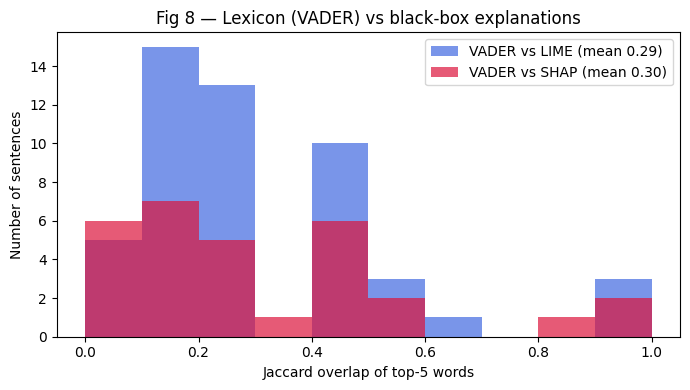


Disagreement examples (VADER∩LIME = 0, but LIME has a strong word):

  Sentence: 'it deserves to be seen by anyone with even a passing interest in the events shaping the world beyond their own horizons . '
  LIME top-5 : [np.str_('a'), np.str_('world'), np.str_('with'), np.str_('even'), np.str_('by')]
  VADER top-5: ['interest', 'it', 'deserves', 'to', 'be']
  VADER compound = 0.459

  Sentence: 'from the opening scenes , it 's clear that all about the benjamins is a totally formulaic movie . '
  LIME top-5 : [np.str_('formulaic'), np.str_('movie'), np.str_('totally'), np.str_('all'), np.str_('about')]
  VADER top-5: ['clear', 'from', 'the', 'opening', 'scenes']
  VADER compound = 0.382

  Sentence: 'it 's one heck of a character study -- not of hearst or davies but of the unique relationship between them . '
  LIME top-5 : [np.str_('but'), np.str_('unique'), np.str_('not'), np.str_('or'), np.str_('a')]
  VADER top-5: ['it', "'s", 'one', 'heck', 'of']
  VADER compound = 0.000


In [14]:
# ============================================================
# CELL 10: Extra B — VADER vs LIME/SHAP + FIG 8
# ============================================================
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

# VADER score on all 872 sentences (fast)
vader_compound = np.array([analyzer.polarity_scores(s)["compound"] for s in sentences])
db_pos = probs_all[:, 1]

from scipy.stats import pearsonr, spearmanr
r_p, _ = pearsonr(vader_compound, db_pos)
r_s, _ = spearmanr(vader_compound, db_pos)
print(f"VADER vs DistilBERT P(POS): Pearson r={r_p:.3f}, Spearman ρ={r_s:.3f}")

# VADER per-word valence for the 50 LIME sentences
def vader_word_weights(text):
    words = text.split()
    out = {}
    for w in words:
        key = w.lower().strip(".,!?;:\"'")
        out[w] = analyzer.lexicon.get(key, 0.0)
    return out

# Compare VADER's non-zero words with LIME / SHAP top-5
vader_top = {}
for i in lime_top:
    vader_top[i] = top_k_words(vader_word_weights(sentences[i]), k=5)

jac_vader_lime = [jaccard(vader_top[i], lime_top[i]) for i in lime_top]
shared_vs = [i for i in shap_top if i in vader_top]
jac_vader_shap = [jaccard(vader_top[i], shap_top[i]) for i in shared_vs]

print(f"Mean Jaccard VADER vs LIME: {np.mean(jac_vader_lime):.3f}")
print(f"Mean Jaccard VADER vs SHAP: {np.mean(jac_vader_shap):.3f}")

# FIG 8: overlap distributions
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(jac_vader_lime, bins=np.linspace(0, 1, 11), alpha=0.7, label=f"VADER vs LIME (mean {np.mean(jac_vader_lime):.2f})", color="royalblue")
ax.hist(jac_vader_shap, bins=np.linspace(0, 1, 11), alpha=0.7, label=f"VADER vs SHAP (mean {np.mean(jac_vader_shap):.2f})", color="crimson")
ax.set_xlabel("Jaccard overlap of top-5 words")
ax.set_ylabel("Number of sentences")
ax.set_title("Fig 8 — Lexicon (VADER) vs black-box explanations")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig8_vader_overlap.pdf", bbox_inches="tight")
plt.savefig("figures/fig8_vader_overlap.png", dpi=150, bbox_inches="tight")
plt.show()

# A few disagreement examples (for the report)
print("\nDisagreement examples (VADER∩LIME = 0, but LIME has a strong word):")
count = 0
for i in lime_top:
    if jaccard(vader_top[i], lime_top[i]) == 0 and count < 3:
        print(f"\n  Sentence: '{sentences[i]}'")
        print(f"  LIME top-5 : {lime_top[i]}")
        print(f"  VADER top-5: {vader_top[i]}")
        print(f"  VADER compound = {analyzer.polarity_scores(sentences[i])['compound']:.3f}")
        count += 1

In [15]:
# ============================================================
# CELL 11: Summary of every number you need
# ============================================================
print("=" * 60)
print("SUMMARY OF KEY NUMBERS")
print("=" * 60)
print(f"Model accuracy          : {acc:.4f}")
print(f"Baseline (majority)     : {baseline:.4f}")
print(f"High-confidence (P>0.99): {(probs_all.max(axis=1) > 0.99).mean():.3f}")
print()
print(f"[Q1] LIME sample n      : {len(lime_top)}")
print(f"[Q1] SHAP sample n      : {len(shap_top)}")
print(f"[Q1] Mean Jaccard LIME/SHAP : {np.mean(overlaps):.3f}")
print()
print(f"[Q2] Mean ΔP LIME top-5 : {df_q2['delta_lime'].mean():.4f}")
print(f"[Q2] Mean ΔP random     : {df_q2['delta_rand'].mean():.4f}")
print(f"[Q2] Wilcoxon p         : {p:.2e}")
print(f"[Q2] Flip rate LIME     : {df_q2['flip_lime'].mean():.3f}")
print(f"[Q2] Flip rate random   : {df_q2['flip_rand'].mean():.3f}")
print()
print(f"[Q3] Mean |ΔP| sentiment pairs: {df_q3['delta'].mean():.4f}")
print(f"[Q3] Mean |ΔP| neutral pairs  : {df_q3_neut['delta'].mean():.4f}")
print(f"[Q3] Flips (sentiment)        : {int(df_q3['flip'].sum())}/{len(df_q3)}")
print()
print(f"[Extra B] Pearson VADER vs DistilBERT: {r_p:.3f}")
print(f"[Extra B] Jaccard VADER vs LIME      : {np.mean(jac_vader_lime):.3f}")
print(f"[Extra B] Jaccard VADER vs SHAP      : {np.mean(jac_vader_shap):.3f}")
print()
print("Figures saved in ./figures/  (PDF + PNG, ready for poster/report)")

SUMMARY OF KEY NUMBERS
Model accuracy          : 0.9106
Baseline (majority)     : 0.5092
High-confidence (P>0.99): 0.844

[Q1] LIME sample n      : 50
[Q1] SHAP sample n      : 30
[Q1] Mean Jaccard LIME/SHAP : 0.407

[Q2] Mean ΔP LIME top-5 : 0.3973
[Q2] Mean ΔP random     : 0.0670
[Q2] Wilcoxon p         : 4.95e-08
[Q2] Flip rate LIME     : 0.400
[Q2] Flip rate random   : 0.080

[Q3] Mean |ΔP| sentiment pairs: 0.0000
[Q3] Mean |ΔP| neutral pairs  : 0.0054
[Q3] Flips (sentiment)        : 0/30

[Extra B] Pearson VADER vs DistilBERT: 0.437
[Extra B] Jaccard VADER vs LIME      : 0.292
[Extra B] Jaccard VADER vs SHAP      : 0.296

Figures saved in ./figures/  (PDF + PNG, ready for poster/report)


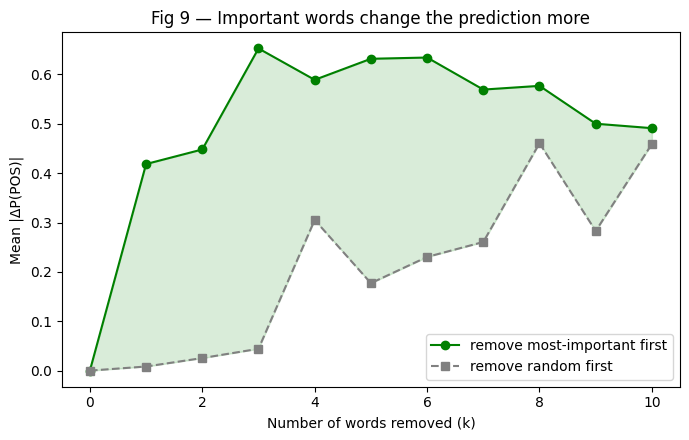

[Fig 9] deletion AUC gap (important - random) = 3.258


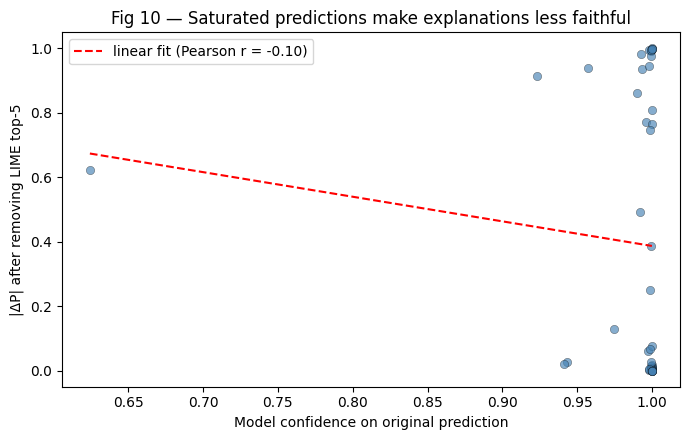

[Fig 10] Pearson(confidence, |ΔP|) = -0.095,  p = 5.11e-01


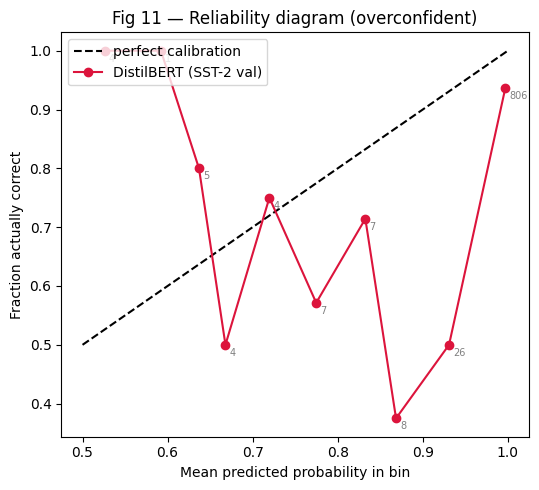

[Fig 11] Expected Calibration Error (ECE) = 0.0803


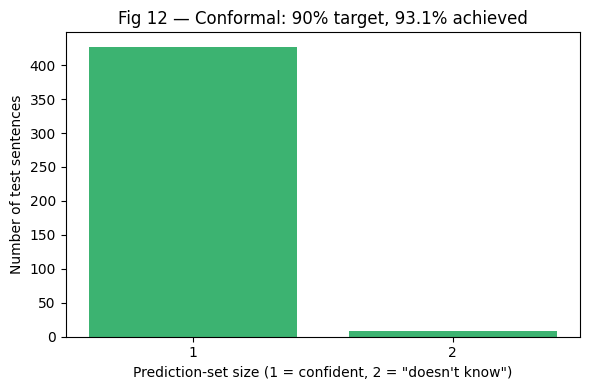

[Fig 12] coverage = 0.931,  mean set size = 1.02,  frac |set|=2 = 0.021


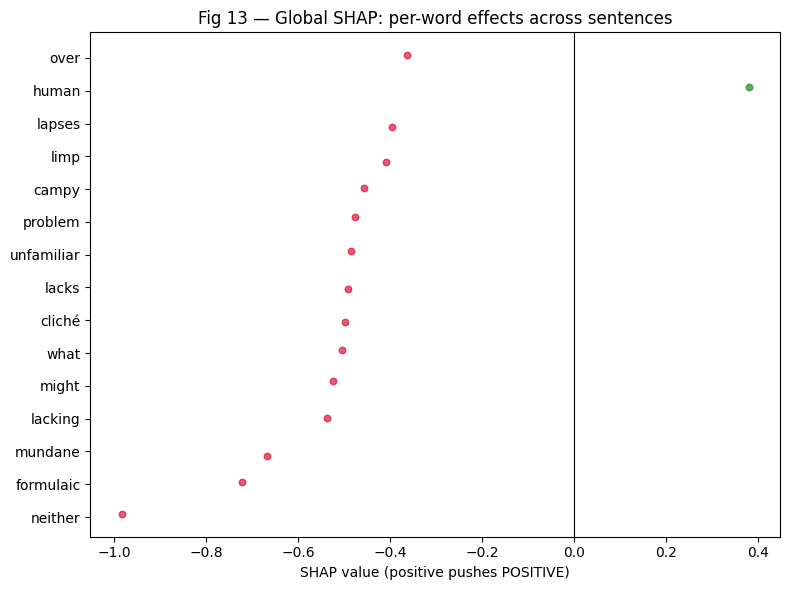

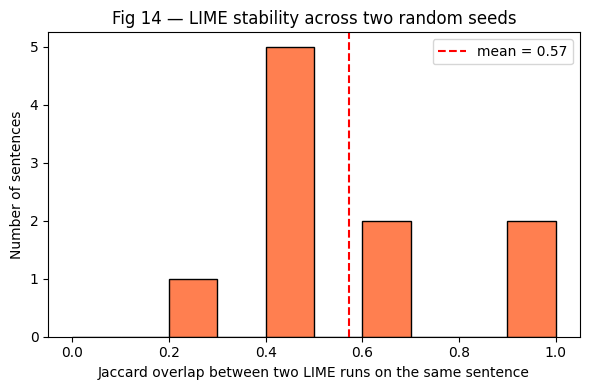

[Fig 14] mean LIME stability Jaccard = 0.573
  'The film is good.'  P=1.000   |   'The film is not good.'  P=0.000   ΔP=1.000
  'The acting was great.'  P=1.000   |   'The acting was not great.'  P=0.000   ΔP=1.000
  'I loved it.'  P=1.000   |   'I did not love it.'  P=0.001   ΔP=0.999
  'The story made sense.'  P=1.000   |   'The story made no sense.'  P=0.000   ΔP=1.000
  'The movie was fun.'  P=1.000   |   'The movie was not fun.'  P=0.000   ΔP=1.000
  'This is the best film.'  P=1.000   |   'This is the worst film.'  P=0.000   ΔP=1.000


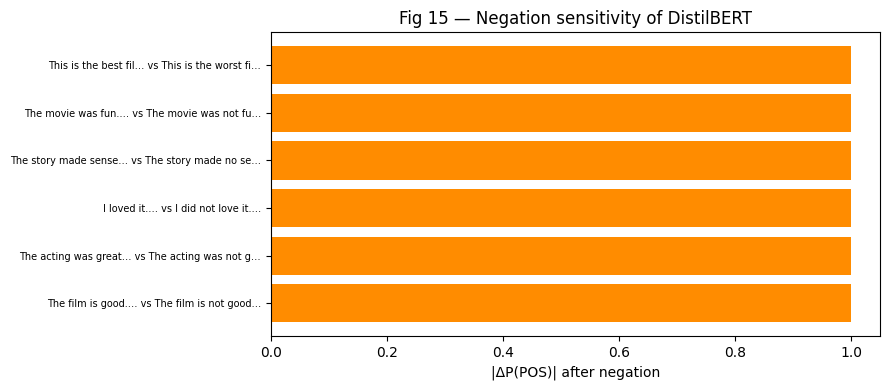


Smallest single-word counterfactuals for misclassified sentences:

  'holden caulfield did it better . …'  P0=0.991
    no single-word removal flips → counterfactual needs > 1 word

  'the script kicks in , and mr. hartley 's distended pace and foot-dragg…'  P0=0.858
    remove 'script' → P=0.032   (FLIP in 1 word)

  'jaglom ... put ( s ) the audience in the privileged position of eavesd…'  P0=0.004
    no single-word removal flips → counterfactual needs > 1 word

  'you wo n't like roger , but you will quickly recognize him . …'  P0=0.999
    no single-word removal flips → counterfactual needs > 1 word

  'if steven soderbergh 's ` solaris ' is a failure it is a glorious fail…'  P0=0.001
    remove 'failure' → P=1.000   (FLIP in 1 word)

SUMMARY OF EXTRA METRICS (Fig 9–16)
[Fig 9 ] Deletion AUC gap             : 3.258
[Fig 10] Pearson(confidence, |ΔP|)    : -0.095   (p = 5.11e-01)
[Fig 11] Expected Calibration Error   : 0.0803
[Fig 12] Conformal coverage @ 90 %    : 93.1 %
[Fig 12] 

In [17]:
# ============================================================
# CELL 12: EXTRA FIGURES (Fig 9–16) + negation check
# ============================================================
# Run AFTER Cell 11. Reuses variables from Cells 1–11.
# Runtime on free Colab CPU: ~4–6 min.
# Produces:
#   Fig 9  — cumulative deletion curve          (Q2, Check)
#   Fig 10 — confidence vs faithfulness         (Q2, Caveat)
#   Fig 11 — reliability diagram + ECE          (Q3)
#   Fig 12 — split conformal prediction         (Q3)
#   Fig 13 — global SHAP beeswarm               (Q1)
#   Fig 14 — LIME stability across seeds        (Q1, Caveat)
#   Fig 15 — negation sensitivity               (Extra B)
#   Fig 16 — smallest single-word counterfactual (Extra A/B)
# ============================================================
from collections import defaultdict
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Fig 9 — Cumulative deletion curve
# ------------------------------------------------------------
def positional_occlusion(text):
    words = text.split()
    base = predict_proba([text])[0, 1]
    variants = [" ".join(words[:j] + words[j+1:]) for j in range(len(words))]
    ps = predict_proba(variants)[:, 1]
    return list(base - ps)

K_MAX = 10
curve_idx = shap_idx[:20]
imp_curves, rand_curves = [], []

for i in curve_idx:
    text = sentences[i]
    words = text.split()
    p0 = predict_proba([text])[0, 1]
    drops = positional_occlusion(text)
    order = list(np.argsort([-abs(d) for d in drops]))
    k_max_i = min(K_MAX, len(words) - 1)

    imp_variants, rand_variants = [], []
    for k in range(K_MAX + 1):
        k_limited = min(k, k_max_i)
        rm = set(order[:k_limited])
        imp_variants.append(" ".join(w for j, w in enumerate(words) if j not in rm))

    rand_variants.append(text)
    for k in range(1, K_MAX + 1):
        k_limited = min(k, len(words))
        rng_k = np.random.default_rng(SEED + i + k)
        rm = set(rng_k.choice(len(words), size=k_limited, replace=False))
        rand_variants.append(" ".join(w for j, w in enumerate(words) if j not in rm))

    all_ps = predict_proba(imp_variants + rand_variants)[:, 1]
    n_i = len(imp_variants)
    imp_curves.append([abs(p0 - p) for p in all_ps[:n_i]])
    rand_curves.append([abs(p0 - p) for p in all_ps[n_i:]])

mean_imp  = np.mean(imp_curves,  axis=0)
mean_rand = np.mean(rand_curves, axis=0)
ks = np.arange(len(mean_imp))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ks, mean_imp,  'o-', color='green', label='remove most-important first')
ax.plot(ks, mean_rand, 's--', color='grey',  label='remove random first')
ax.fill_between(ks, mean_imp, mean_rand, alpha=0.15, color='green')
ax.set_xlabel('Number of words removed (k)')
ax.set_ylabel('Mean |ΔP(POS)|')
ax.set_title('Fig 9 — Important words change the prediction more')
ax.legend()
plt.tight_layout()
plt.savefig('figures/fig9_deletion_curve.pdf', bbox_inches='tight')
plt.savefig('figures/fig9_deletion_curve.png', dpi=150, bbox_inches='tight')
plt.show()
auc_gap = mean_imp.sum() - mean_rand.sum()
print(f"[Fig 9] deletion AUC gap (important - random) = {auc_gap:.3f}")

# ------------------------------------------------------------
# Fig 10 — Confidence vs faithfulness
# ------------------------------------------------------------
conf_q2 = np.maximum(df_q2['p0'], 1 - df_q2['p0'])
r_10, p_10 = pearsonr(conf_q2, df_q2['delta_lime'])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(conf_q2, df_q2['delta_lime'], alpha=0.65, c='steelblue',
           edgecolor='k', linewidth=0.3)
z = np.polyfit(conf_q2, df_q2['delta_lime'], 1)
xs = np.linspace(conf_q2.min(), conf_q2.max(), 50)
ax.plot(xs, np.polyval(z, xs), 'r--', label=f'linear fit (Pearson r = {r_10:.2f})')
ax.set_xlabel('Model confidence on original prediction')
ax.set_ylabel('|ΔP| after removing LIME top-5')
ax.set_title('Fig 10 — Saturated predictions make explanations less faithful')
ax.legend()
plt.tight_layout()
plt.savefig('figures/fig10_confidence_vs_delta.pdf', bbox_inches='tight')
plt.savefig('figures/fig10_confidence_vs_delta.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"[Fig 10] Pearson(confidence, |ΔP|) = {r_10:.3f},  p = {p_10:.2e}")

# ------------------------------------------------------------
# Fig 11 — Reliability diagram + ECE
# ------------------------------------------------------------
conf    = probs_all.max(axis=1)
correct = (preds_all == labels).astype(float)

bins = np.linspace(0.5, 1.0, 11)
bin_c, bin_a, bin_n = [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    m = (conf >= lo) & (conf < hi)
    if m.sum() > 0:
        bin_c.append(conf[m].mean())
        bin_a.append(correct[m].mean())
        bin_n.append(int(m.sum()))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0.5, 1.0], [0.5, 1.0], 'k--', label='perfect calibration')
ax.plot(bin_c, bin_a, 'o-', color='crimson', label='DistilBERT (SST-2 val)')
for c, a, n in zip(bin_c, bin_a, bin_n):
    ax.annotate(str(n), (c, a), fontsize=7, color='grey',
                xytext=(3, -8), textcoords='offset points')
ax.set_xlabel('Mean predicted probability in bin')
ax.set_ylabel('Fraction actually correct')
ax.set_title('Fig 11 — Reliability diagram (overconfident)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('figures/fig11_reliability.pdf', bbox_inches='tight')
plt.savefig('figures/fig11_reliability.png', dpi=150, bbox_inches='tight')
plt.show()
ece = np.sum([n * abs(c - a) for c, a, n in zip(bin_c, bin_a, bin_n)]) / len(sentences)
print(f"[Fig 11] Expected Calibration Error (ECE) = {ece:.4f}")

# ------------------------------------------------------------
# Fig 12 — Split conformal prediction (90 % target)
# ------------------------------------------------------------
cal_idx, test_idx = train_test_split(
    np.arange(len(sentences)), test_size=0.5, random_state=SEED, stratify=labels)

cal_scores = 1 - probs_all[cal_idx, labels[cal_idx]]
alpha = 0.10
q = np.quantile(cal_scores, 1 - alpha)

test_p     = probs_all[test_idx]
test_y     = labels[test_idx]
set_sizes  = (test_p >= (1 - q)).sum(axis=1)
covered    = (test_p[np.arange(len(test_idx)), test_y] >= (1 - q))

fig, ax = plt.subplots(figsize=(6, 4))
uniq, cnts = np.unique(set_sizes, return_counts=True)
ax.bar(uniq, cnts, color='mediumseagreen')
ax.set_xticks([1, 2])
ax.set_xlabel('Prediction-set size (1 = confident, 2 = "doesn\'t know")')
ax.set_ylabel('Number of test sentences')
ax.set_title(f'Fig 12 — Conformal: {100*(1-alpha):.0f}% target, '
             f'{covered.mean()*100:.1f}% achieved')
plt.tight_layout()
plt.savefig('figures/fig12_conformal.pdf', bbox_inches='tight')
plt.savefig('figures/fig12_conformal.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"[Fig 12] coverage = {covered.mean():.3f},  mean set size = {set_sizes.mean():.2f},  "
      f"frac |set|=2 = {(set_sizes==2).mean():.3f}")

# ------------------------------------------------------------
# Fig 13 — Global SHAP beeswarm
# ------------------------------------------------------------
word_shap = defaultdict(list)
for k in range(len(shap_idx)):
    tokens = list(shap_values[k].data)
    vals   = np.array(shap_values[k].values).flatten()
    for tok, v in zip(tokens, vals):
        key = normalize_word(tok)
        if key and len(key) > 2:
            word_shap[key].append(v)

top15_shap = sorted(word_shap, key=lambda w: -np.mean(np.abs(word_shap[w])))[:15]

fig, ax = plt.subplots(figsize=(8, 6))
for r, w in enumerate(top15_shap):
    vals = np.array(word_shap[w])
    jit  = np.random.default_rng(SEED + r).uniform(-0.18, 0.18, size=len(vals))
    colors = ['forestgreen' if v > 0 else 'crimson' for v in vals]
    ax.scatter(vals, r + jit, c=colors, alpha=0.7, s=22)
ax.set_yticks(range(len(top15_shap)))
ax.set_yticklabels(top15_shap)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('SHAP value (positive pushes POSITIVE)')
ax.set_title('Fig 13 — Global SHAP: per-word effects across sentences')
plt.tight_layout()
plt.savefig('figures/fig13_shap_beeswarm.pdf', bbox_inches='tight')
plt.savefig('figures/fig13_shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# Fig 14 — LIME stability (two seeds)
# ------------------------------------------------------------
def lime_top5(text, seed):
    np.random.seed(seed)
    exp = lime_explainer.explain_instance(text, predict_proba,
                                          num_features=10, num_samples=300,
                                          labels=(1,))
    try:    w = dict(exp.as_list(label=1))
    except TypeError: w = dict(exp.as_list())
    return top_k_words(w, k=5)

stab_idx = sample_idx[:10]
stab = []
for i in stab_idx:
    t1 = lime_top5(sentences[i], seed=SEED)
    t2 = lime_top5(sentences[i], seed=SEED + 1)
    stab.append(jaccard(t1, t2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(stab, bins=np.linspace(0, 1, 11), edgecolor='k', color='coral')
ax.axvline(np.mean(stab), color='red', ls='--', label=f'mean = {np.mean(stab):.2f}')
ax.set_xlabel('Jaccard overlap between two LIME runs on the same sentence')
ax.set_ylabel('Number of sentences')
ax.set_title('Fig 14 — LIME stability across two random seeds')
ax.legend()
plt.tight_layout()
plt.savefig('figures/fig14_lime_stability.pdf', bbox_inches='tight')
plt.savefig('figures/fig14_lime_stability.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"[Fig 14] mean LIME stability Jaccard = {np.mean(stab):.3f}")

# ------------------------------------------------------------
# Fig 15 — Negation sensitivity (Extra B supporting evidence)
# ------------------------------------------------------------
neg_pairs = [
    ("The film is good.",       "The film is not good."),
    ("The acting was great.",   "The acting was not great."),
    ("I loved it.",             "I did not love it."),
    ("The story made sense.",   "The story made no sense."),
    ("The movie was fun.",      "The movie was not fun."),
    ("This is the best film.",  "This is the worst film."),
]
neg_labels = []
neg_deltas = []
for a, b in neg_pairs:
    pa = predict_proba([a])[0, 1]
    pb = predict_proba([b])[0, 1]
    neg_deltas.append(abs(pa - pb))
    neg_labels.append(f"{a[:20]}… vs {b[:20]}…")
    print(f"  '{a}'  P={pa:.3f}   |   '{b}'  P={pb:.3f}   ΔP={abs(pa-pb):.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(range(len(neg_deltas)), neg_deltas, color='darkorange')
ax.set_yticks(range(len(neg_deltas)))
ax.set_yticklabels(neg_labels, fontsize=7)
ax.set_xlabel('|ΔP(POS)| after negation')
ax.set_title('Fig 15 — Negation sensitivity of DistilBERT')
plt.tight_layout()
plt.savefig('figures/fig15_negation.pdf', bbox_inches='tight')
plt.savefig('figures/fig15_negation.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# Fig 16 — Smallest single-word counterfactual for misclassified cases
# ------------------------------------------------------------
misclassified = np.where(preds_all != labels)[0]
print("\nSmallest single-word counterfactuals for misclassified sentences:\n")
shown = 0
for i in misclassified:
    if shown >= 5: break
    text = sentences[i]
    p0   = probs_all[i, 1]
    lab0 = int(p0 > 0.5)
    words = text.split()
    if len(words) < 4:
        continue
    variants = [" ".join(words[:j] + words[j+1:]) for j in range(len(words))]
    ps = predict_proba(variants)[:, 1]
    flips = [(words[j], float(ps[j])) for j in range(len(words))
             if int(ps[j] > 0.5) != lab0]
    if flips:
        w, p_new = flips[0]
        print(f"  '{text[:70]}…'  P0={p0:.3f}")
        print(f"    remove '{w}' → P={p_new:.3f}   (FLIP in 1 word)\n")
    else:
        print(f"  '{text[:70]}…'  P0={p0:.3f}")
        print(f"    no single-word removal flips → counterfactual needs > 1 word\n")
    shown += 1

# ------------------------------------------------------------
# Summary of all new metrics
# ------------------------------------------------------------
print("=" * 60)
print("SUMMARY OF EXTRA METRICS (Fig 9–16)")
print("=" * 60)
print(f"[Fig 9 ] Deletion AUC gap             : {auc_gap:.3f}")
print(f"[Fig 10] Pearson(confidence, |ΔP|)    : {r_10:.3f}   (p = {p_10:.2e})")
print(f"[Fig 11] Expected Calibration Error   : {ece:.4f}")
print(f"[Fig 12] Conformal coverage @ 90 %    : {covered.mean()*100:.1f} %")
print(f"[Fig 12] Mean prediction-set size     : {set_sizes.mean():.2f}")
print(f"[Fig 12] Fraction |set|=2 (undecided) : {(set_sizes==2).mean():.3f}")
print(f"[Fig 14] LIME stability Jaccard       : {np.mean(stab):.3f}")
print(f"[Fig 15] Mean |ΔP| under negation     : {np.mean(neg_deltas):.3f}")
print()
print("All figures saved in ./figures/  (PDF + PNG, ready for poster/report)")

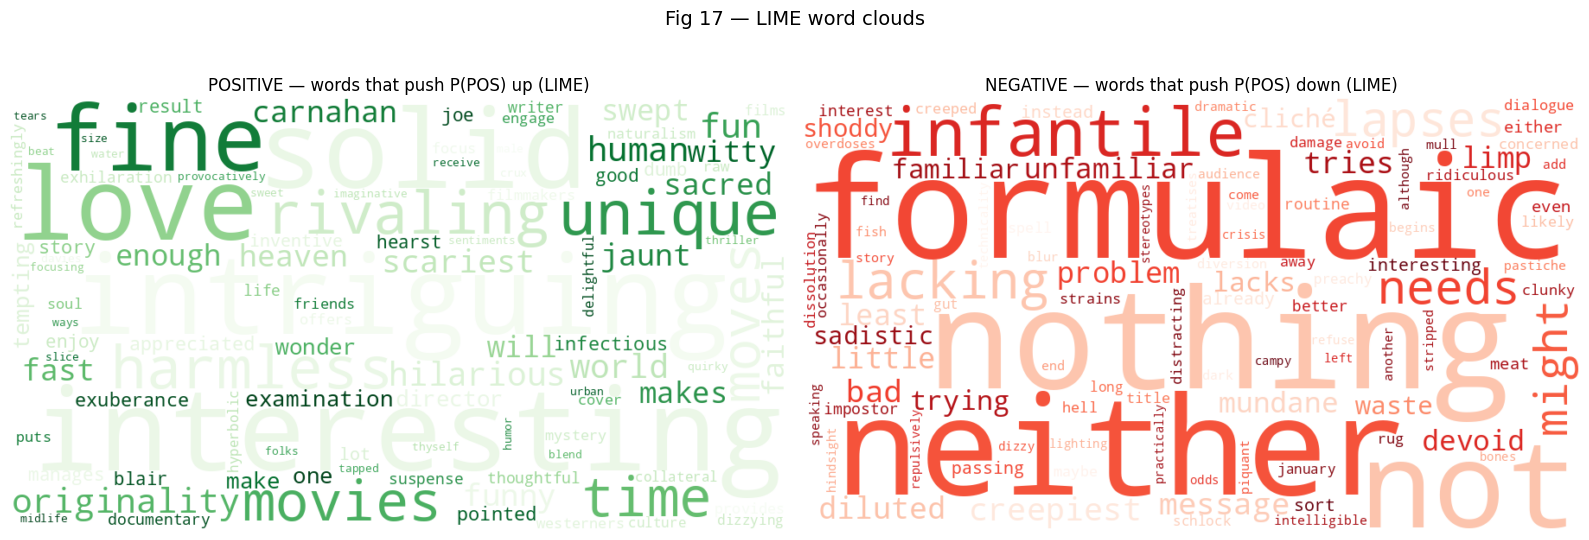

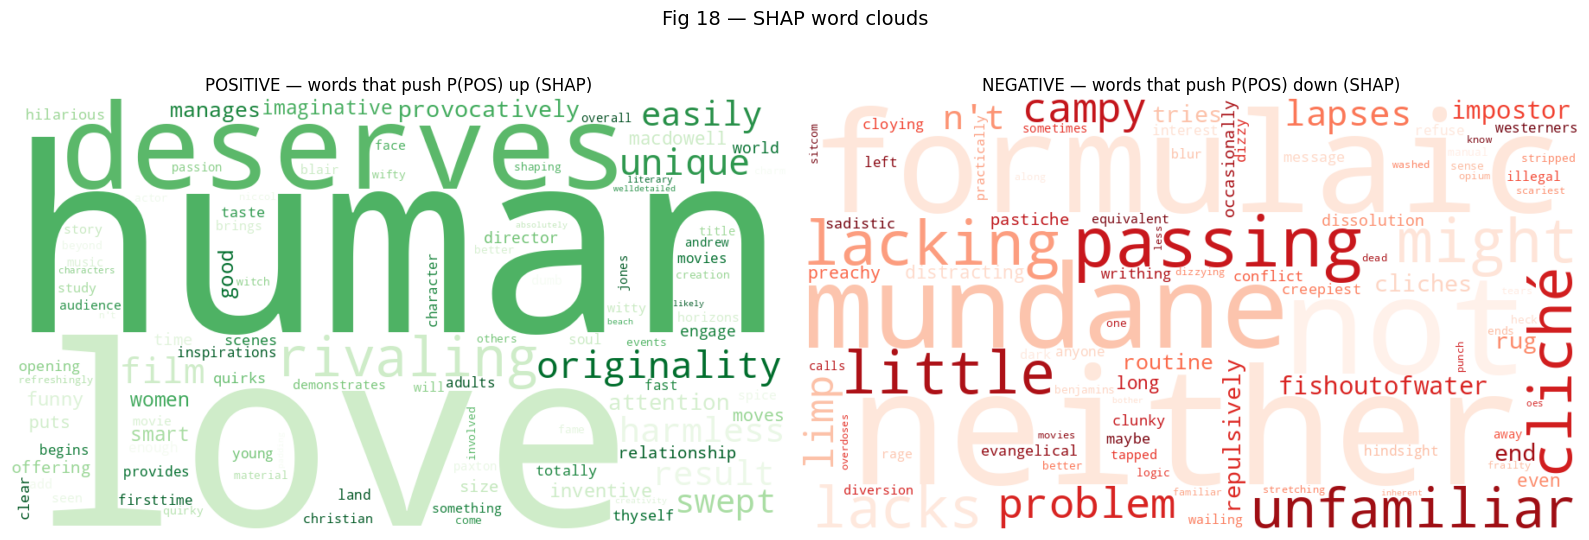

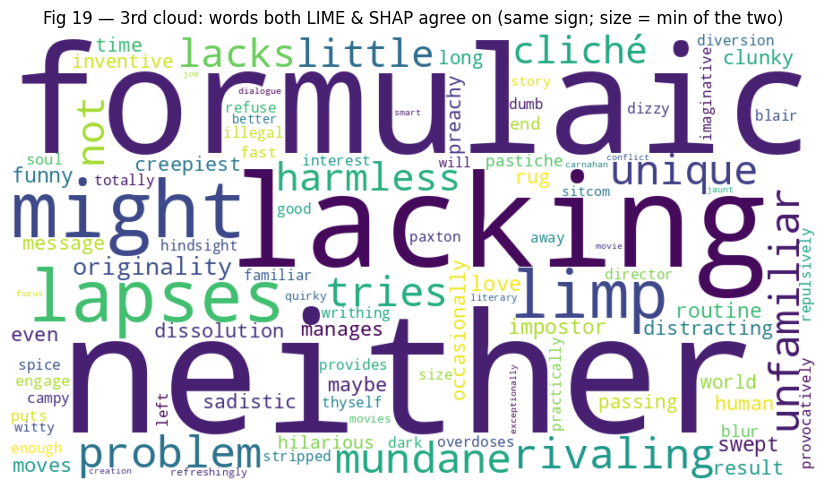

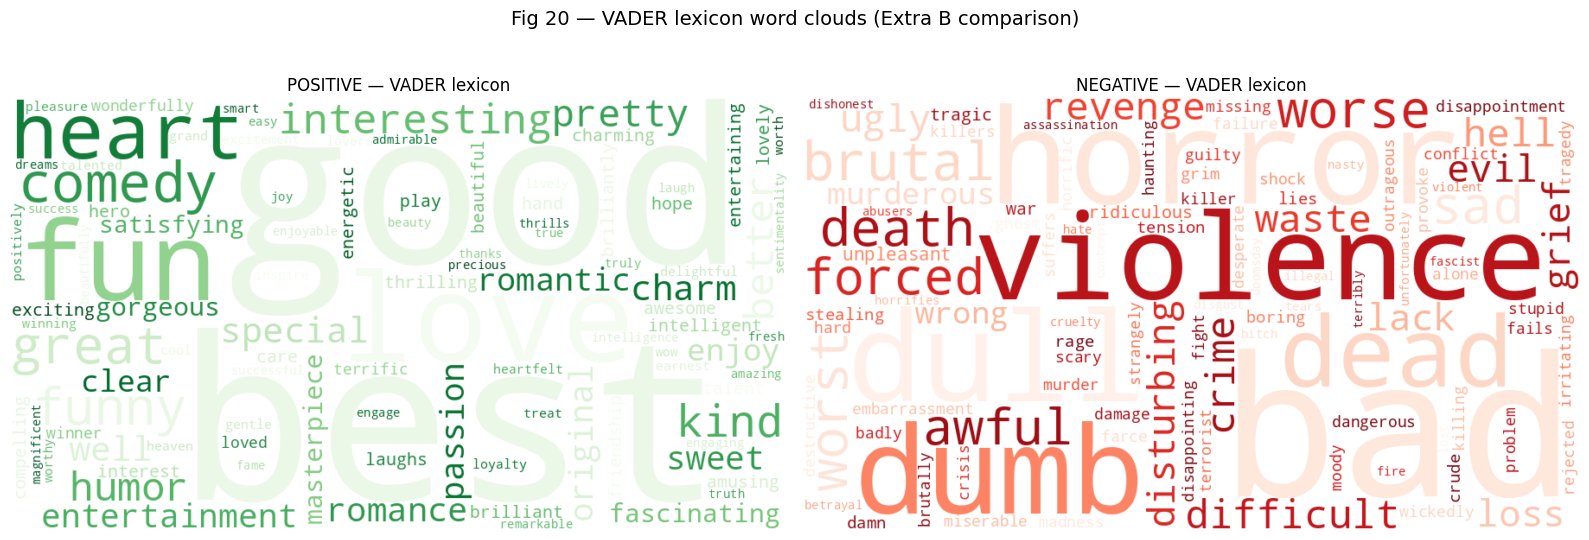


WORD CLOUD SUMMARY
LIME positive  : 149 unique words
LIME negative  : 123 unique words
SHAP positive  : 139 unique words
SHAP negative  : 108 unique words
Consensus (3rd): 128 words (same sign in both methods)
VADER positive : 399 unique words
VADER negative : 316 unique words

Top-10 words by weight in each cloud:
  LIME+     : ['interesting', 'solid', 'intriguing', 'love', 'fine', 'unique', 'rivaling', 'harmless', 'movies', 'time']
  LIME-     : ['formulaic', 'nothing', 'neither', 'not', 'infantile', 'lacking', 'lapses', 'needs', 'might', 'creepiest']
  SHAP+     : ['human', 'love', 'deserves', 'rivaling', 'originality', 'unique', 'film', 'harmless', 'swept', 'easily']
  SHAP-     : ['neither', 'formulaic', 'not', 'mundane', 'passing', 'lacking', 'might', 'little', 'cliché', 'lacks']
  CONSENSUS : ['neither', 'formulaic', 'lacking', 'might', 'lapses', 'limp', 'problem', 'mundane', 'rivaling', 'unfamiliar']
  VADER+    : ['best', 'good', 'love', 'fun', 'heart', 'comedy', 'great', 'fu

In [18]:
# ============================================================
# CELL 13: Word clouds — LIME, SHAP, 3rd consensus cloud, VADER bonus
# Produces Fig 17, 18, 19, 20.
# Run AFTER Cell 12. Uses lime_full, shap_values, shap_idx,
# probs_all, sentences, analyzer, normalize_word (from Cells 3–10).
# ============================================================
!pip install -q wordcloud

import re
from collections import defaultdict
from wordcloud import WordCloud, STOPWORDS

# ---- keep negations; filter other stopwords and short words ----
KEEP_NEG = {"not", "no", "never", "none", "nothing", "nobody", "nowhere",
            "neither", "nor", "n't", "cannot", "cant", "wont", "dont",
            "doesnt", "didnt", "isnt", "wasnt", "arent", "werent"}
STOP = set(STOPWORDS) - KEEP_NEG

def keep(w):
    w_n = normalize_word(w)
    return bool(w_n) and w_n not in STOP and len(w_n) >= 3

# ---- LIME clouds ----
def build_lime_clouds():
    pos, neg = defaultdict(float), defaultdict(float)
    for weights in lime_full.values():
        for w, v in weights.items():
            if not keep(w): continue
            w_n = normalize_word(w)
            if v > 0:   pos[w_n] += v
            elif v < 0: neg[w_n] += abs(v)
    return dict(pos), dict(neg)

# ---- SHAP clouds ----
def build_shap_clouds():
    pos, neg = defaultdict(float), defaultdict(float)
    for k in range(len(shap_idx)):
        tokens = list(shap_values[k].data)
        vals   = np.array(shap_values[k].values).flatten()
        for tok, v in zip(tokens, vals):
            if not keep(tok): continue
            w_n = normalize_word(tok)
            if v > 0:   pos[w_n] += v
            elif v < 0: neg[w_n] += abs(v)
    return dict(pos), dict(neg)

# ---- 3rd cloud: consensus (both methods, same sign, min of the two) ----
def build_consensus_cloud():
    lm = defaultdict(list)
    for w_dict in lime_full.values():
        for w, v in w_dict.items():
            if keep(w): lm[normalize_word(w)].append(v)
    lm = {w: float(np.mean(vs)) for w, vs in lm.items()}

    sm = defaultdict(list)
    for k in range(len(shap_idx)):
        tokens = list(shap_values[k].data)
        vals   = np.array(shap_values[k].values).flatten()
        for tok, v in zip(tokens, vals):
            if keep(tok): sm[normalize_word(tok)].append(v)
    sm = {w: float(np.mean(vs)) for w, vs in sm.items()}

    cons = {}
    for w in set(lm) & set(sm):
        l, s = lm[w], sm[w]
        if (l > 0) == (s > 0):          # agree on direction
            cons[w] = min(abs(l), abs(s))   # conservative strength
    return cons

# ---- VADER clouds (bonus for Extra B) ----
def build_vader_clouds():
    pos, neg = defaultdict(float), defaultdict(float)
    for s in sentences:
        for w in s.split():
            if not keep(w): continue
            w_n = normalize_word(w)
            v = analyzer.lexicon.get(w_n, 0.0)
            if v > 0:   pos[w_n] += v
            elif v < 0: neg[w_n] += abs(v)
    return dict(pos), dict(neg)

# ---- drawing helpers ----
def draw_cloud(ax, freq, title, cmap):
    if not freq:
        ax.text(0.5, 0.5, "(no words)", ha='center', va='center', fontsize=14)
        ax.axis('off'); return
    wc = WordCloud(width=900, height=500, background_color='white',
                   colormap=cmap, max_words=100, prefer_horizontal=0.95,
                   relative_scaling=0.5, min_font_size=10,
                   random_state=SEED).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=12)

def save_fig(fig, name):
    fig.savefig(f'figures/{name}.pdf', bbox_inches='tight')
    fig.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

# ---- generate all ----
lime_pos, lime_neg     = build_lime_clouds()
shap_pos, shap_neg     = build_shap_clouds()
consensus              = build_consensus_cloud()
vader_pos, vader_neg   = build_vader_clouds()

# Fig 17 — LIME
fig, ax = plt.subplots(1, 2, figsize=(16, 6), facecolor='white')
draw_cloud(ax[0], lime_pos, "POSITIVE — words that push P(POS) up (LIME)",  "Greens")
draw_cloud(ax[1], lime_neg, "NEGATIVE — words that push P(POS) down (LIME)", "Reds")
fig.suptitle("Fig 17 — LIME word clouds", fontsize=14)
plt.tight_layout()
save_fig(fig, "fig17_lime_clouds"); plt.show()

# Fig 18 — SHAP
fig, ax = plt.subplots(1, 2, figsize=(16, 6), facecolor='white')
draw_cloud(ax[0], shap_pos, "POSITIVE — words that push P(POS) up (SHAP)",  "Greens")
draw_cloud(ax[1], shap_neg, "NEGATIVE — words that push P(POS) down (SHAP)", "Reds")
fig.suptitle("Fig 18 — SHAP word clouds", fontsize=14)
plt.tight_layout()
save_fig(fig, "fig18_shap_clouds"); plt.show()

# Fig 19 — 3rd cloud: consensus between LIME and SHAP
fig, ax = plt.subplots(figsize=(10, 5), facecolor='white')
draw_cloud(ax, consensus,
           "Fig 19 — 3rd cloud: words both LIME & SHAP agree on (same sign; size = min of the two)",
           "viridis")
plt.tight_layout()
save_fig(fig, "fig19_consensus_cloud"); plt.show()

# Fig 20 — VADER (bonus Extra B)
fig, ax = plt.subplots(1, 2, figsize=(16, 6), facecolor='white')
draw_cloud(ax[0], vader_pos, "POSITIVE — VADER lexicon",  "Greens")
draw_cloud(ax[1], vader_neg, "NEGATIVE — VADER lexicon",  "Reds")
fig.suptitle("Fig 20 — VADER lexicon word clouds (Extra B comparison)", fontsize=14)
plt.tight_layout()
save_fig(fig, "fig20_vader_clouds"); plt.show()

# ---- summary you can paste into the report ----
print("\n" + "=" * 60)
print("WORD CLOUD SUMMARY")
print("=" * 60)
print(f"LIME positive  : {len(lime_pos):3d} unique words")
print(f"LIME negative  : {len(lime_neg):3d} unique words")
print(f"SHAP positive  : {len(shap_pos):3d} unique words")
print(f"SHAP negative  : {len(shap_neg):3d} unique words")
print(f"Consensus (3rd): {len(consensus):3d} words (same sign in both methods)")
print(f"VADER positive : {len(vader_pos):3d} unique words")
print(f"VADER negative : {len(vader_neg):3d} unique words")
print("\nTop-10 words by weight in each cloud:")
for name, d in [("LIME+", lime_pos), ("LIME-", lime_neg),
                ("SHAP+", shap_pos), ("SHAP-", shap_neg),
                ("CONSENSUS", consensus),
                ("VADER+", vader_pos), ("VADER-", vader_neg)]:
    top = sorted(d, key=lambda w: -d[w])[:10]
    print(f"  {name:10s}: {top}")
print("\nFigures 17–20 saved to ./figures/ (PDF + PNG)")